# 02 - Training Data Exploration

Training-only class balance, reproducible examples, full Pillow decoding and exact duplicate audit. Every labelled row is retained. Raw files are read only; test images are never accessed. No splitting, augmentation or modelling is performed.

## 1. Project root, environment and labelled rows

Use the established structural project-root detection. All image paths are constructed exclusively from the verified training IDs and training directory.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from importlib.metadata import version
import hashlib
import json
import struct
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ExifTags
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks" / "00_Environment_Check.ipynb").is_file():
            return candidate
    raise FileNotFoundError("Open this project root or its notebooks directory.")

PROJECT_ROOT = find_project_root(Path.cwd())
# These lightweight path checks do not repeat the audit.
assert find_project_root(PROJECT_ROOT) == PROJECT_ROOT
assert find_project_root(PROJECT_ROOT / "notebooks") == PROJECT_ROOT
assert Path(sys.prefix).resolve() == (PROJECT_ROOT / ".venv").resolve()
assert Path(sys.executable).resolve().parent == PROJECT_ROOT / ".venv" / "Scripts"
assert not ImageFile.LOAD_TRUNCATED_IMAGES, "Do not enable tolerant truncated-image decoding."

contract = json.loads((PROJECT_ROOT / "outputs/metrics/data_access_check.json").read_text(encoding="utf-8"))
assert not contract["failed_checks"]
TRAIN_DIR = (PROJECT_ROOT / contract["images"]["train_directory"]).resolve()
assert TRAIN_DIR == (PROJECT_ROOT / "data/raw/train/train").resolve()
labels_path = PROJECT_ROOT / "data/raw/train_labels.csv"
labels = pd.read_csv(labels_path, dtype=str, keep_default_na=False, na_filter=False)
assert list(labels.columns) == ["image_id", "class"]
assert len(labels) == contract["csv"]["train"]["row_count"]
assert labels["image_id"].str.fullmatch(r"[0-9]{5}").all()
assert not labels["image_id"].duplicated().any()
assert not labels.eq("").any().any()
classes = sorted(labels["class"].unique())
assert classes == contract["training_classes"]

FIGURES = PROJECT_ROOT / "outputs/figures"
METRICS = PROJECT_ROOT / "outputs/metrics"
MANIFEST_PATH = PROJECT_ROOT / "data/processed/training_manifest.csv"
GROUPS_PATH = METRICS / "training_duplicate_groups.csv"
AUDIT_PATH = METRICS / "training_data_audit.json"
for directory in [FIGURES, METRICS, MANIFEST_PATH.parent]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "savefig.dpi": 150})
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Labelled rows retained:", len(labels))


Project: C:\Users\leoca\Kaggle-Competition
Python: C:\Users\leoca\Kaggle-Competition\.venv\Scripts\python.exe
Labelled rows retained: 63660


## 2. Class counts and percentages

Counts use every original labelled row, without filtering or balancing. Percentages use the full training-row count.

,count,percentage
class,,
CatEye,13884,21.81%
CatFace,6942,10.90%
CatMouth,6942,10.90%
CatNose,6942,10.90%
DogEye,11580,18.19%
DogFace,5790,9.10%
DogMouth,5790,9.10%
DogNose,5790,9.10%


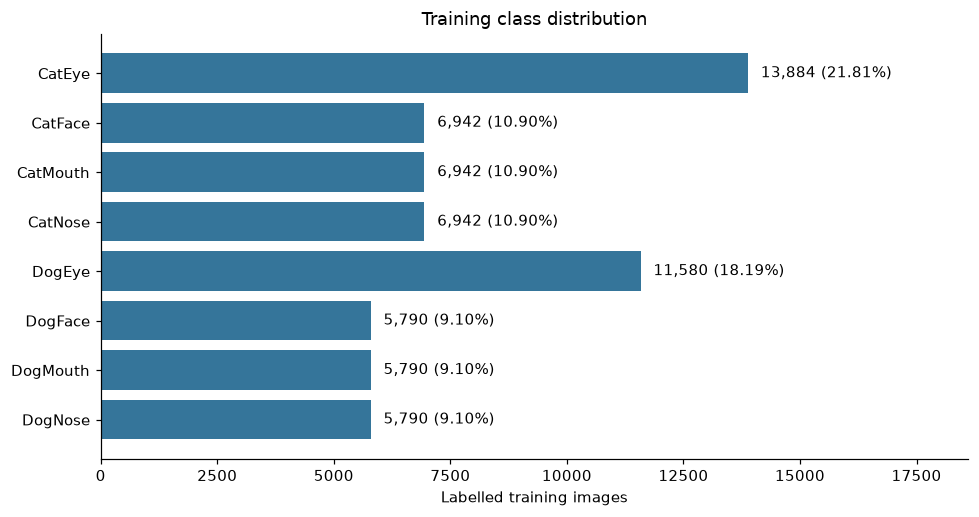

Largest/smallest class ratio: 2.398


In [2]:
counts = labels["class"].value_counts().reindex(classes)
distribution = counts.rename("count").to_frame()
distribution.index.name = "class"
distribution["percentage"] = 100 * distribution["count"] / len(labels)
display(distribution.style.format({"percentage": "{:.2f}%"}))

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(classes, counts, color="#35759A")
for bar, count, percentage in zip(bars, counts, distribution["percentage"]):
    ax.text(count + counts.max() * 0.02, bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({percentage:.2f}%)", va="center")
ax.set(xlabel="Labelled training images", title="Training class distribution", xlim=(0, counts.max() * 1.34))
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
CLASS_FIGURE = FIGURES / "training_class_distribution.png"
fig.savefig(CLASS_FIGURE)
plt.show()
plt.close(fig)
print("Largest/smallest class ratio:", round(float(counts.max() / counts.min()), 3))


## 3. Decode and hash every training image

Process one image at a time. `Image.load()` forces decoding; all frames are decoded if an unexpected multi-frame file is encountered. Pillow's truncated-file tolerance remains disabled. Warnings are captured with their categories and messages, stored per image and summarised explicitly. Errors retain the row and any header metadata already available.

**Byte hash:** SHA-256 of the unchanged complete file. **Pixel hash:** SHA-256 of `b"ENGE707-RGB-v1\0"`, unsigned 64-bit big-endian width and height, then row-major bytes from Pillow `convert("RGB")` on frame 0. No EXIF transposition, resizing, normalisation or ICC colour management is applied. Pixel equality is exact under this decoder, not perceptual similarity. The RGB conversion is for hashing/display only and does not change raw files.

In [3]:
records = []
metadata_key_counts = Counter()
exif_tag_counts = Counter()
format_counts = Counter()

for position, (image_id, label) in enumerate(labels.itertuples(index=False, name=None), start=1):
    path = TRAIN_DIR / f"{image_id}.jpg"
    record = {
        "image_id": image_id, "class": label,
        "image_path": path.relative_to(PROJECT_ROOT).as_posix(),
        "width": None, "height": None, "mode": "", "format": "", "frame_count": None,
        "decode_status": "error", "decode_error": "", "decode_warnings": "[]",
        "byte_sha256": "", "pixel_sha256": "", "byte_hash_error": "",
    }
    # Hash the unchanged file in a stream; do not retain file bytes in memory.
    try:
        with path.open("rb") as stream:
            record["byte_sha256"] = hashlib.file_digest(stream, "sha256").hexdigest()
    except Exception as error:
        record["byte_hash_error"] = f"{type(error).__name__}: {error}"

    extra_warnings = []
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            with Image.open(path) as image:
                record.update(width=image.width, height=image.height, mode=image.mode,
                              format=image.format or "", frame_count=getattr(image, "n_frames", 1))
                format_counts[record["format"]] += 1
                metadata_key_counts.update(str(key) for key in image.info)
                image.load()
                # Record available metadata fields, without inferring animal/source identities.
                try:
                    exif_tag_counts.update(str(ExifTags.TAGS.get(tag, tag)) for tag in image.getexif())
                except Exception as error:
                    extra_warnings.append({"category": "MetadataReadWarning", "message": f"{type(error).__name__}: {error}"})
                for frame in range(1, record["frame_count"]):
                    image.seek(frame)
                    image.load()
                image.seek(0)
                with image.convert("RGB") as rgb:
                    rgb.load()
                    pixel_digest = hashlib.sha256()
                    pixel_digest.update(b"ENGE707-RGB-v1\0")
                    pixel_digest.update(struct.pack(">QQ", rgb.width, rgb.height))
                    pixel_digest.update(rgb.tobytes())
                    record["pixel_sha256"] = pixel_digest.hexdigest()
                record["decode_status"] = "ok"
        except Exception as error:
            record["decode_error"] = f"{type(error).__name__}: {error}"
    image_warnings = [{"category": item.category.__name__, "message": str(item.message)} for item in caught] + extra_warnings
    record["decode_warnings"] = json.dumps(image_warnings)
    if image_warnings and record["decode_status"] == "ok":
        record["decode_status"] = "warning"
    records.append(record)
    if position % 5000 == 0 or position == len(labels):
        print(f"Audited {position:,}/{len(labels):,} training files", flush=True)

manifest = pd.DataFrame.from_records(records)
for column in ["width", "height", "frame_count"]:
    manifest[column] = manifest[column].astype("Int64")
manifest.to_csv(MANIFEST_PATH, index=False)
decoded = manifest[manifest["decode_status"].isin(["ok", "warning"])].copy()
decoded["aspect_ratio"] = decoded["width"].astype(float) / decoded["height"].astype(float)

warning_counts = Counter()
warning_image_ids = []
for row in manifest.itertuples(index=False):
    entries = json.loads(row.decode_warnings)
    if entries:
        warning_image_ids.append(row.image_id)
    warning_counts.update((entry["category"], entry["message"]) for entry in entries)
errors = manifest[manifest["decode_status"].eq("error")]
print("Decode status:", manifest["decode_status"].value_counts().to_dict())
print("Warning messages and occurrence counts:", dict(warning_counts))
print("Decode errors:", errors[["image_id", "decode_error"]].to_dict("records"))
print("File-hash errors:", manifest.loc[manifest["byte_hash_error"].ne(""), ["image_id", "byte_hash_error"]].to_dict("records"))


Audited 5,000/63,660 training files


Audited 10,000/63,660 training files


Audited 15,000/63,660 training files


Audited 20,000/63,660 training files


Audited 25,000/63,660 training files


...

Audited 50,000/63,660 training files


Audited 55,000/63,660 training files


Audited 60,000/63,660 training files


Audited 63,660/63,660 training files


Decode status: {'ok': 63660}
Warning messages and occurrence counts: {}
Decode errors: []
File-hash errors: []


## 4. Dimensions, aspect ratios and original modes

Dimension statistics and the figure use successfully decoded images, including those with recorded warnings. The manifest retains header dimensions even if decoding fails. Aspect ratio is original width divided by original height; display/hashing does not rotate EXIF-oriented images.

Original modes: {'RGB': 63660}
Unique decoded dimensions: 7861


,width,height,aspect_ratio
count,63660.000000,63660.000000,63660.000000
mean,113.095209,109.737857,1.063526
std,98.491801,101.911146,0.189017
min,4.000000,4.000000,0.402632
25%,54.000000,50.000000,1.000000
50%,84.000000,80.000000,1.000000
75%,138.000000,130.000000,1.000000
max,2219.000000,2219.000000,10.000000


,,count
width,height,
40,40,1062
48,48,1051
42,42,1050
44,44,1002
38,38,1002
46,46,985
34,34,978
36,36,963
54,54,952


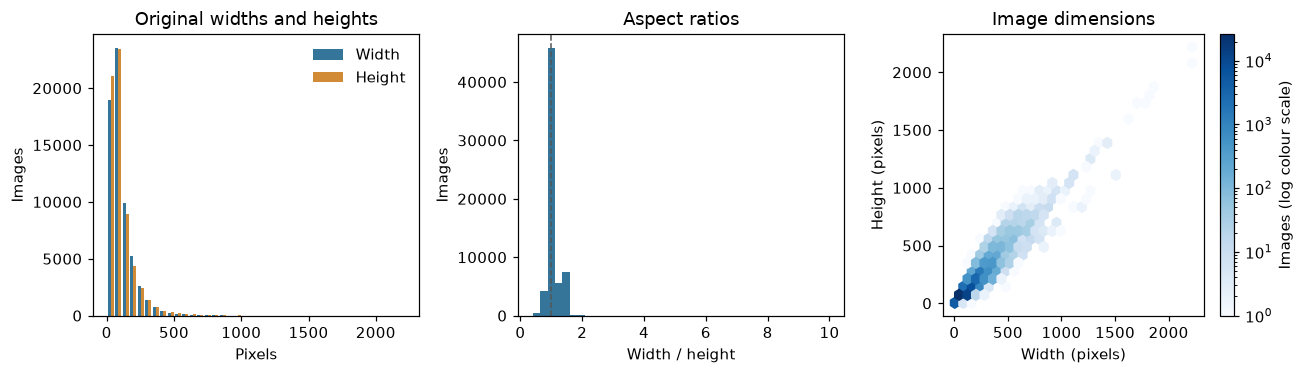

In [4]:
dimension_summary = json.loads(decoded[["width", "height", "aspect_ratio"]].astype(float).describe().to_json())
mode_counts = {str(key): int(value) for key, value in manifest["mode"].value_counts().items()}
size_counts = decoded.groupby(["width", "height"]).size().sort_values(ascending=False)
print("Original modes:", mode_counts)
print("Unique decoded dimensions:", len(size_counts))
display(decoded[["width", "height", "aspect_ratio"]].astype(float).describe())
display(size_counts.head(10).rename("count").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
if len(decoded):
    widths = decoded["width"].to_numpy(dtype=float)
    heights = decoded["height"].to_numpy(dtype=float)
    low, high = min(widths.min(), heights.min()), max(widths.max(), heights.max())
    bins = np.linspace(low - 0.5, high + 0.5, 41)
    axes[0].hist([widths, heights], bins=bins, label=["Width", "Height"], color=["#35759A", "#D18A36"])
    axes[0].legend(frameon=False)
    axes[1].hist(decoded["aspect_ratio"], bins=40, color="#35759A")
    axes[1].axvline(1, color="#555555", linestyle="--", linewidth=1)
    density = axes[2].hexbin(widths, heights, gridsize=28, mincnt=1, bins="log", cmap="Blues")
    fig.colorbar(density, ax=axes[2], label="Images (log colour scale)")
axes[0].set(xlabel="Pixels", ylabel="Images", title="Original widths and heights")
axes[1].set(xlabel="Width / height", ylabel="Images", title="Aspect ratios")
axes[2].set(xlabel="Width (pixels)", ylabel="Height (pixels)", title="Image dimensions")
fig.tight_layout()
DIMENSION_FIGURE = FIGURES / "training_dimension_distribution.png"
fig.savefig(DIMENSION_FIGURE)
plt.show()
plt.close(fig)


## 5. Reproducible training gallery

Select three original labelled rows per class using NumPy seed 42, sorted class order and original CSV row order. Preserve aspect ratios in each panel. If a selected image cannot decode, show the error rather than silently replacing it.

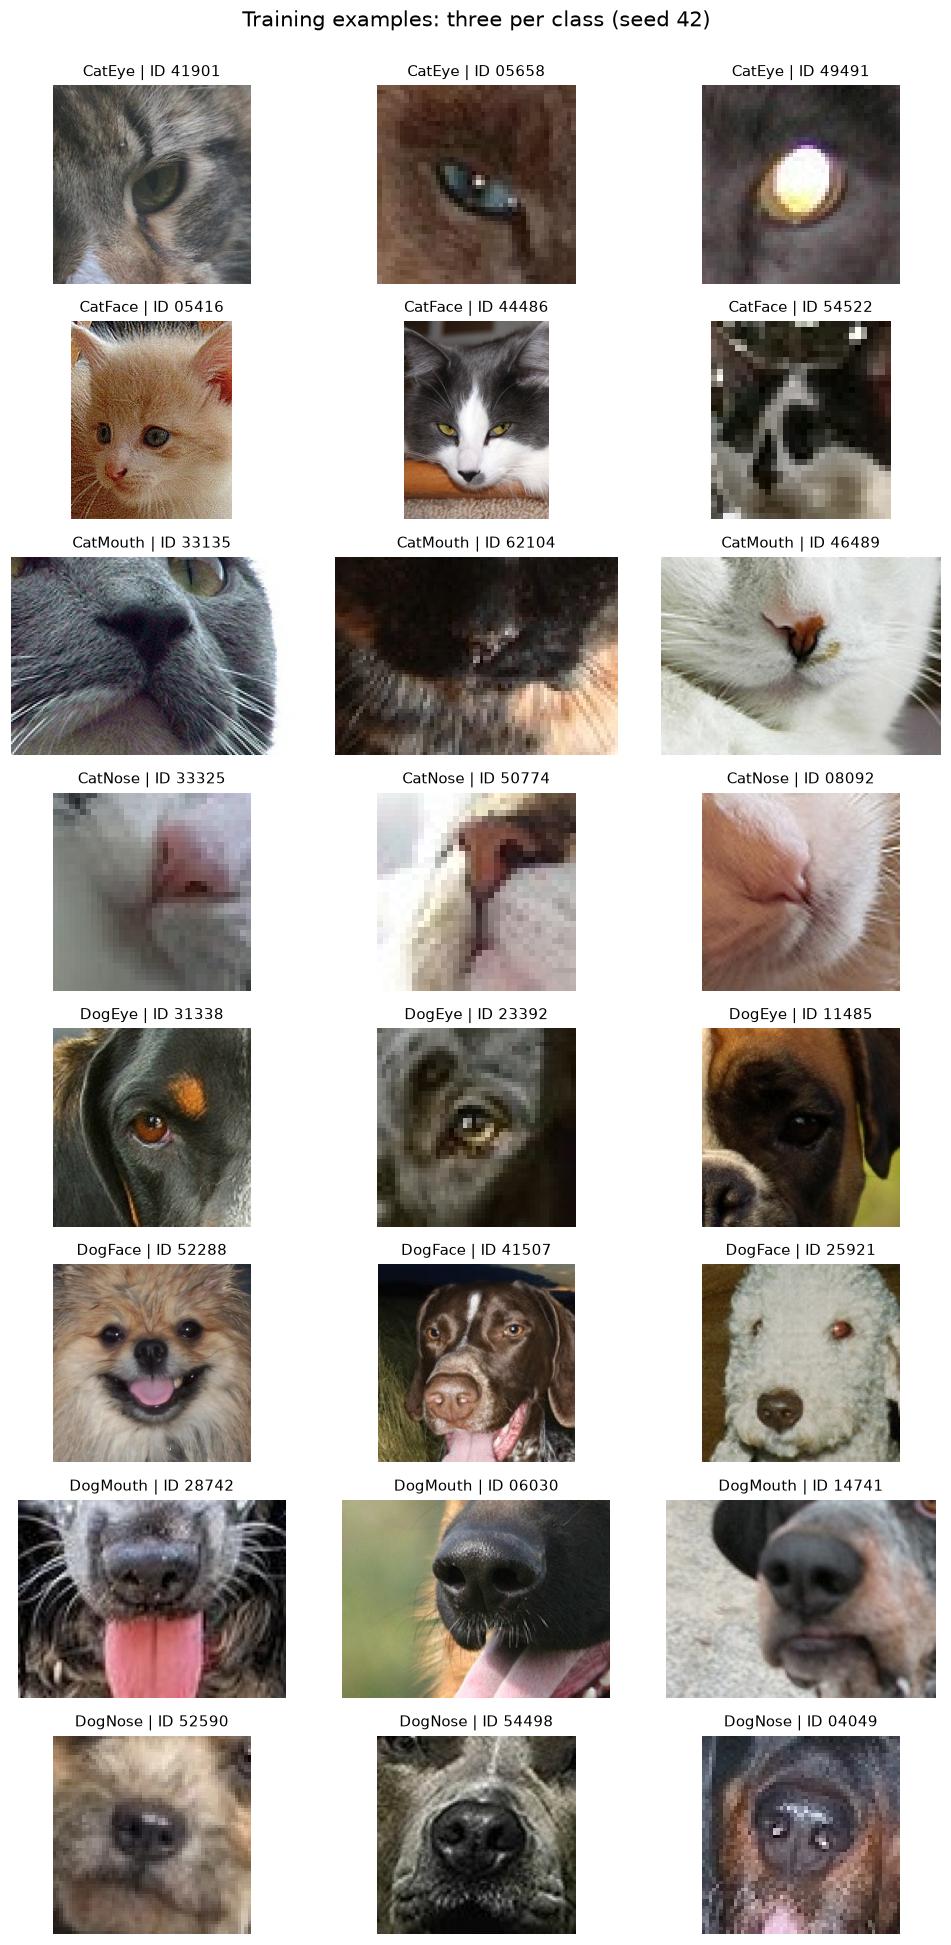

Gallery decode errors: []


In [5]:
rng = np.random.default_rng(42)
gallery_rows = []
for label in classes:
    candidates = labels.index[labels["class"].eq(label)].to_numpy()
    for index in rng.choice(candidates, size=3, replace=False):
        gallery_rows.append(labels.loc[index].to_dict())

fig, axes = plt.subplots(len(classes), 3, figsize=(9, 18), squeeze=False)
gallery_errors = []
for ax, row in zip(axes.flat, gallery_rows):
    path = TRAIN_DIR / f"{row['image_id']}.jpg"
    try:
        with Image.open(path) as image:
            image.load()
            with image.convert("RGB") as rgb:
                ax.imshow(np.asarray(rgb), aspect="equal")
    except Exception as error:
        message = f"{type(error).__name__}: {error}"
        gallery_errors.append({"image_id": row["image_id"], "error": message})
        ax.text(0.5, 0.5, "Decode error\nSee manifest", ha="center", va="center")
    ax.set_title(f"{row['class']} | ID {row['image_id']}", fontsize=10)
    ax.axis("off")
fig.suptitle("Training examples: three per class (seed 42)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.98))
GALLERY_FIGURE = FIGURES / "training_gallery_seed42.png"
fig.savefig(GALLERY_FIGURE)
plt.show()
plt.close(fig)
print("Gallery decode errors:", gallery_errors)


## 6. Exact duplicate membership and label conflicts

Byte-identical groups share complete file bytes. Pixel-identical groups share canonical RGB pixels and dimensions and may contain different file encodings or metadata. Groups overlap across types; do not add their affected-image counts. Consistent-label groups still require keeping related copies together during a future split. Conflicting labels require a decision; this audit does not relabel or remove anything. These hashes do not detect all near-duplicates or related crops.

In [6]:
memberships = []
duplicate_summary = {}
for duplicate_type, hash_column in [("byte", "byte_sha256"), ("pixel", "pixel_sha256")]:
    eligible = manifest[manifest[hash_column].ne("")]
    duplicate_rows = eligible[eligible[hash_column].duplicated(keep=False)]
    consistent = conflicting = different_encodings = 0
    for digest, group in duplicate_rows.groupby(hash_column, sort=True):
        status = "conflicting" if group["class"].nunique() > 1 else "consistent"
        conflicting += status == "conflicting"
        consistent += status == "consistent"
        if duplicate_type == "pixel" and group["byte_sha256"].nunique() > 1:
            different_encodings += 1
        for image_id, label in group[["image_id", "class"]].itertuples(index=False, name=None):
            memberships.append({
                "duplicate_type": duplicate_type, "group_id": f"{duplicate_type}:{digest}",
                "image_id": image_id, "class": label, "group_size": len(group), "label_status": status,
            })
    duplicate_summary[duplicate_type] = {
        "groups": int(consistent + conflicting), "affected_images": int(len(duplicate_rows)),
        "consistent_label_groups": int(consistent), "conflicting_label_groups": int(conflicting),
        "conflicting_label_images": int(duplicate_rows.groupby(hash_column).filter(lambda group: group["class"].nunique() > 1).shape[0]),
    }
    if duplicate_type == "pixel":
        duplicate_summary[duplicate_type]["groups_with_different_file_bytes"] = int(different_encodings)

groups = pd.DataFrame(memberships, columns=["duplicate_type", "group_id", "image_id", "class", "group_size", "label_status"])
groups.to_csv(GROUPS_PATH, index=False)
duplicate_summary["unique_affected_images_across_types"] = int(groups["image_id"].nunique())
duplicate_summary["unique_conflicting_images_across_types"] = int(groups.loc[groups["label_status"].eq("conflicting"), "image_id"].nunique())
print(json.dumps(duplicate_summary, indent=2))
if not groups.empty:
    display(groups.head(12))


{
  "byte": {
    "groups": 15,
    "affected_images": 30,
    "consistent_label_groups": 15,
    "conflicting_label_groups": 0,
    "conflicting_label_images": 0
  },
  "pixel": {
    "groups": 15,
    "affected_images": 30,
    "consistent_label_groups": 15,
    "conflicting_label_groups": 0,
    "conflicting_label_images": 0,
    "groups_with_different_file_bytes": 0
  },
  "unique_affected_images_across_types": 30,
  "unique_conflicting_images_across_types": 0
}


,duplicate_type,group_id,image_id,class,group_size,label_status
0,byte,byte:17106d9033c707b67a96b97e1b0172d6f67cc401a...,13090,CatEye,2,consistent
1,byte,byte:17106d9033c707b67a96b97e1b0172d6f67cc401a...,63140,CatEye,2,consistent
2,byte,byte:431fa9fed49f3a5b69ddcf69dc60f0d4aa6d1bb41...,30201,DogEye,2,consistent
3,byte,byte:431fa9fed49f3a5b69ddcf69dc60f0d4aa6d1bb41...,50179,DogEye,2,consistent
4,byte,byte:5f3585161d586ec6d62c649a57c150345ad53a886...,35039,DogFace,2,consistent
5,byte,byte:5f3585161d586ec6d62c649a57c150345ad53a886...,55965,DogFace,2,consistent
6,byte,byte:670b19e2359dd4b163c4d194de1d05d16b585fdcb...,03926,CatEye,2,consistent
7,byte,byte:670b19e2359dd4b163c4d194de1d05d16b585fdcb...,56008,CatEye,2,consistent
8,byte,byte:8909d512fbb5ae6578e4811c2a11015bf3f0cfe92...,54348,CatEye,2,consistent
9,byte,byte:8909d512fbb5ae6578e4811c2a11015bf3f0cfe92...,57804,CatEye,2,consistent


## 7. Provenance, saved summary and verification

Available provenance is the supplied competition archive, training CSV and individual crop files. Numeric filenames are row identifiers, not verified animal/source groups. Embedded metadata field names are counted below, but no animal identities or source grouping are inferred. Unknown related crops and near-duplicates may remain, so exact-hash grouping alone cannot establish full independence. No provenance has been fetched externally.

In [7]:
checks = {}
def check(name, condition):
    checks[name] = bool(condition)
    print(f"{name}: {'PASS' if condition else 'FAIL'}")

# Reload outputs with IDs as strings: verify persistence and row order without re-decoding.
saved_manifest = pd.read_csv(MANIFEST_PATH, dtype=str, keep_default_na=False, na_filter=False)
saved_groups = pd.read_csv(GROUPS_PATH, dtype=str, keep_default_na=False, na_filter=False)
check("manifest_covers_every_labelled_row_in_original_order", saved_manifest[["image_id", "class"]].equals(labels))
check("manifest_rows_equal_expected_count", len(manifest) == contract["csv"]["train"]["row_count"])
check("class_counts_total", int(distribution["count"].sum()) == len(labels))
check("class_percentages_total", np.isclose(distribution["percentage"].sum(), 100))
check("all_paths_training_only", all(Path(path).parent.as_posix() == "data/raw/train/train" for path in saved_manifest["image_path"]))
check("every_row_has_recorded_decode_outcome", manifest["decode_status"].isin(["ok", "warning", "error"]).all())
check("successful_decodes_have_dimensions_and_pixel_hashes", (decoded["width"].gt(0) & decoded["height"].gt(0) & decoded["pixel_sha256"].str.fullmatch(r"[0-9a-f]{64}")).all())
check("byte_hashes_or_errors_recorded", (manifest["byte_sha256"].str.fullmatch(r"[0-9a-f]{64}") | manifest["byte_hash_error"].ne("")).all())

membership_consistent = True
for duplicate_type, hash_column in [("byte", "byte_sha256"), ("pixel", "pixel_sha256")]:
    eligible = saved_manifest[saved_manifest[hash_column].ne("")]
    expected = eligible[eligible[hash_column].duplicated(keep=False)]
    actual = saved_groups[saved_groups["duplicate_type"].eq(duplicate_type)]
    membership_consistent &= set(actual["image_id"]) == set(expected["image_id"])
    membership_consistent &= not actual["image_id"].duplicated().any()
    for group_id, members in actual.groupby("group_id"):
        joined = members.merge(saved_manifest[["image_id", "class", hash_column]], on="image_id", validate="one_to_one", suffixes=("", "_manifest"))
        expected_status = "conflicting" if joined["class"].nunique() > 1 else "consistent"
        membership_consistent &= len(members) >= 2 and joined[hash_column].nunique() == 1
        membership_consistent &= group_id == f"{duplicate_type}:{joined[hash_column].iloc[0]}"
        membership_consistent &= joined["class"].equals(joined["class_manifest"])
        membership_consistent &= members["group_size"].eq(str(len(members))).all()
        membership_consistent &= members["label_status"].eq(expected_status).all()
check("duplicate_group_membership_sizes_hashes_and_labels_consistent", membership_consistent)
check("gallery_three_per_class", len(gallery_rows) == 3 * len(classes) and all(sum(row["class"] == label for row in gallery_rows) == 3 for label in classes))
check("gallery_rendered_without_errors", not gallery_errors)
outputs = [MANIFEST_PATH, GROUPS_PATH, CLASS_FIGURE, DIMENSION_FIGURE, GALLERY_FIGURE]
check("saved_outputs_exist_and_nonempty", all(path.is_file() and path.stat().st_size > 0 for path in outputs))

limitations = [
    "Exact file and decoded RGB hashes do not detect all near-duplicates, related crops or shared animals/sources.",
    "No verified animal/source group identifiers are available in the label CSV; numeric filenames are not treated as groups.",
    "Pixel hash uses Pillow RGB conversion and frame 0 without EXIF rotation, ICC management or resizing; decoder/version differences can affect equality.",
    "Byte and pixel duplicate groups overlap; keep their union together when making a future leakage-safe split.",
    "No raw files, labels or rows were changed; no split, augmentation, model or training was created.",
]
quality = {
    "decode_status_counts": {str(key): int(value) for key, value in manifest["decode_status"].value_counts().items()},
    "unreadable_image_count": int(len(errors)),
    "decode_errors": errors[["image_id", "decode_error"]].to_dict("records"),
    "warning_image_count": len(warning_image_ids),
    "warning_image_ids": warning_image_ids,
    "warning_messages": [{"category": category, "message": message, "occurrences": count} for (category, message), count in sorted(warning_counts.items())],
    "byte_hash_error_count": int(manifest["byte_hash_error"].ne("").sum()),
    "byte_hash_errors": manifest.loc[manifest["byte_hash_error"].ne(""), ["image_id", "byte_hash_error"]].to_dict("records"),
    "multi_frame_image_count": int(manifest["frame_count"].gt(1).sum()),
    "format_counts": dict(format_counts), "original_mode_counts": mode_counts,
    "dimension_statistics_successful_decodes": dimension_summary,
    "unique_decoded_dimensions": int(len(size_counts)),
    "most_common_dimensions": [{"width": int(width), "height": int(height), "count": int(count)} for (width, height), count in size_counts.head(10).items()],
}
summary = {
    "checked_at": datetime.now().astimezone().isoformat(),
    "training_rows": len(labels), "manifest_rows": len(manifest),
    "class_distribution": json.loads(distribution.reset_index().to_json(orient="records")),
    "largest_smallest_class_ratio": float(counts.max() / counts.min()),
    "quality": quality, "duplicates": duplicate_summary,
    "hashing": {
        "byte": "SHA-256 over complete original file bytes, streamed.",
        "pixel": "SHA-256 over b'ENGE707-RGB-v1\\0' + struct.pack('>QQ', width, height) + row-major uint8 Pillow convert('RGB') bytes of frame 0; no EXIF transpose or ICC transform.",
        "pillow_version": version("Pillow"),
        "group_id": "duplicate_type + ':' + full SHA-256 digest; memberships saved for future splitting.",
    },
    "provenance": {
        "label_columns": list(labels.columns),
        "archive_name": Path(contract["archive"]["path"]).name,
        "training_labels": labels_path.relative_to(PROJECT_ROOT).as_posix(),
        "training_directory": TRAIN_DIR.relative_to(PROJECT_ROOT).as_posix(),
        "embedded_metadata_key_counts": dict(sorted(metadata_key_counts.items())),
        "exif_tag_name_counts": dict(sorted(exif_tag_counts.items())),
        "verified_animal_or_source_groups": None,
    },
    "gallery": {"seed": 42, "selection": gallery_rows, "errors": gallery_errors},
    "execution": {"python_executable": sys.executable, "kernel_name": "enge707-assessment3", "working_directory": str(Path.cwd()), "full_audit_runs_this_execution": 1},
    "outputs": [path.relative_to(PROJECT_ROOT).as_posix() for path in outputs] + [AUDIT_PATH.relative_to(PROJECT_ROOT).as_posix()],
    "checks": checks, "failed_checks": [name for name, passed in checks.items() if not passed],
    "limitations": limitations,
}
decisions = ["Assess unknown related crops/near-duplicates and unavailable animal/source provenance before choosing a splitting strategy."]
if duplicate_summary["unique_affected_images_across_types"]:
    decisions.append("Keep overlapping byte/pixel duplicate memberships together in any later split; do not count overlapping groups twice.")
if duplicate_summary["unique_conflicting_images_across_types"]:
    decisions.append("Decide how to handle identical-image groups with conflicting labels before splitting; no labels were changed.")
if len(errors) or warning_image_ids or quality["byte_hash_error_count"]:
    decisions.append("Review recorded decoding warnings/errors and hash failures before deciding any image-handling policy; all rows remain retained.")
summary["decisions_before_splitting"] = decisions
AUDIT_PATH.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
# Confirm the machine-readable summary itself can be read after saving.
assert json.loads(AUDIT_PATH.read_text(encoding="utf-8"))["manifest_rows"] == len(labels)
print("Embedded metadata fields:", summary["provenance"]["embedded_metadata_key_counts"])
print("EXIF fields:", summary["provenance"]["exif_tag_name_counts"])
print("Saved:", AUDIT_PATH.relative_to(PROJECT_ROOT))
assert not summary["failed_checks"], summary["failed_checks"]
print("All audit-output verification checks passed. Quality findings remain recorded for review.")


manifest_covers_every_labelled_row_in_original_order: PASS
manifest_rows_equal_expected_count: PASS
class_counts_total: PASS
class_percentages_total: PASS


all_paths_training_only: PASS
every_row_has_recorded_decode_outcome: PASS
successful_decodes_have_dimensions_and_pixel_hashes: PASS
byte_hashes_or_errors_recorded: PASS


duplicate_group_membership_sizes_hashes_and_labels_consistent: PASS
gallery_three_per_class: PASS
gallery_rendered_without_errors: PASS
saved_outputs_exist_and_nonempty: PASS
Embedded metadata fields: {'jfif': 63660, 'jfif_density': 63660, 'jfif_unit': 63660, 'jfif_version': 63660}
EXIF fields: {}
Saved: outputs\metrics\training_data_audit.json
All audit-output verification checks passed. Quality findings remain recorded for review.
